# **Marketing Campaign Performance Analysis**
**Company:** NourishMart

**Project Type:** Pandas,NumPy,Matplotlib,Seaborn,Google Colab

**# Business Objective**
To analyze customer purchasing behaviour, evaluate marketing campaign performance, identify business opperunites, and automate repetitive reporting tasks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [2]:
import os
print("Files available in Colab:")
print(os.listdir("/content"))

Files available in Colab:
['.config', 'drive', 'sample_data']


In [8]:
def load_data():
  files_path="/content/ifood_df.csv"

  df=pd.read_csv(files_path)
  print("Data loaded successfully")
  return df

In [9]:
df=load_data()
print(df.head())

Data loaded successfully
    Income  Kidhome  Teenhome  Recency  MntWines  MntFruits  MntMeatProducts  \
0  58138.0        0         0       58       635         88              546   
1  46344.0        1         1       38        11          1                6   
2  71613.0        0         0       26       426         49              127   
3  26646.0        1         0       26        11          4               20   
4  58293.0        1         0       94       173         43              118   

   MntFishProducts  MntSweetProducts  MntGoldProds  ...  marital_Together  \
0              172                88            88  ...                 0   
1                2                 1             6  ...                 0   
2              111                21            42  ...                 1   
3               10                 3             5  ...                 1   
4               46                27            15  ...                 0   

   marital_Widow  education_2n 

In [11]:
def validate_data(df):
  print("Number of Rows:",df.shape[0])
  print("Number of Coumns:",df.shape[1])
  print("/nMissing Values:")
  missing_values = df.isnull().sum()
  missing_values = missing_values[missing_values > 0]

  if missing_values.empty:
    print("No missing values found")
  else:
    print(missing_values)
  return df




In [12]:
validate_data(df)

Number of Rows: 2205
Number of Coumns: 39
/nMissing Values:
No missing values found


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,0,0,1,0,0,1529,1441,0
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,0,1,0,0,21,15,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,1,0,0,0,1,0,0,734,692,0
3,26646.0,1,0,26,11,4,20,10,3,5,...,1,0,0,0,1,0,0,48,43,0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,0,0,1,407,392,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2200,61223.0,0,1,46,709,43,182,42,118,247,...,0,0,0,0,1,0,0,1094,847,0
2201,64014.0,2,1,56,406,0,30,0,0,8,...,1,0,0,0,0,0,1,436,428,1
2202,56981.0,0,0,91,908,48,217,32,12,24,...,0,0,0,0,1,0,0,1217,1193,1
2203,69245.0,0,1,8,428,30,214,80,30,61,...,1,0,0,0,0,1,0,782,721,0


In [13]:
def cleaned_data(df):
  median_income=df["Income"].median()
  df["Income"]=df["Income"].fillna(median_income)
  df=df[df['Income']<300000].reset_index(drop=True)
  return df

In [14]:
df=load_data()

Data loaded successfully


In [15]:
df=cleaned_data(df)

In [17]:
def create_features(df):
  df["Total_Spend"]=(df['MntWines']+ df['MntMeatProducts']+df['MntFishProducts']+df['MntFruits']+df['MntSweetProducts']+df['MntGoldProds'])
  return df


In [18]:
df=create_features(df)

In [19]:
def find_segment(spend):
  if spend < 500:
    return 'Low Spender'
  elif spend < 2000:
    return 'Medium Spender'
  else:
    return 'High Spender'

In [20]:
df['Customer_Segment']=df['Total_Spend'].apply(find_segment)
df.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Total_Spend,Customer_Segment
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,1,0,0,1529,1441,0,1617,Medium Spender
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,1,0,0,21,15,0,27,Low Spender
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,0,1,0,0,734,692,0,776,Medium Spender
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,0,1,0,0,48,43,0,53,Low Spender
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,1,407,392,0,422,Low Spender


In [21]:
def calculation_kpi(df):
  overall_response = df['Response'].mean()*100
  avg_spend = df['Total_Spend'].mean()
  complaint_rate = df['Complain'].mean()*100
  print("Overall responds rate",overall_response)
  print('Average spend rate',avg_spend)
  print('Complain rate',complaint_rate)


In [22]:
def create_visualization(df):
    plt.figure(figsize=(8,5))
    cmp_cols= ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
    cmp_means = [
        df['AcceptedCmp1'].mean() * 100,
        df['AcceptedCmp2'].mean() * 100,
        df['AcceptedCmp3'].mean() * 100,
        df['AcceptedCmp4'].mean() * 100,
        df['AcceptedCmp5'].mean() * 100,
        df['Response'].mean() * 100
    ]
    sns.barplot(x=cmp_cols, y=cmp_means, palette="magma")
    plt.title("Marketing Campaign Acceptance Rates")
    plt.ylabel("Acceptance Rate (%)")
    plt.xticks(rotation=15)
    plt.show()

/tmp/ipykernel_1152/3802124309.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cmp_cols, y=cmp_means, palette="magma")


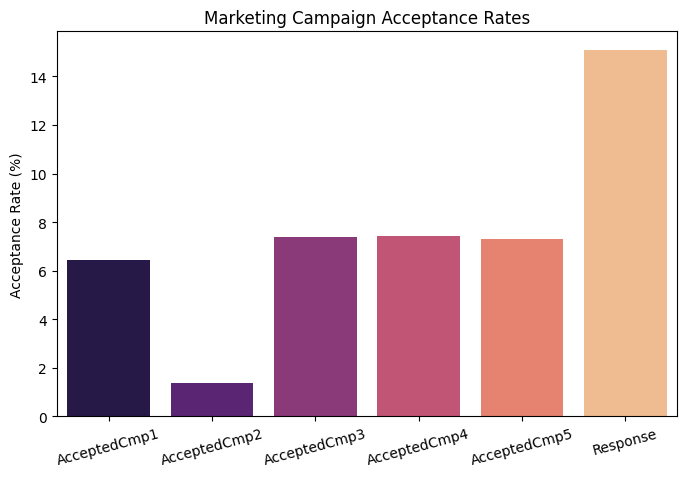

In [23]:
create_visualization(df)

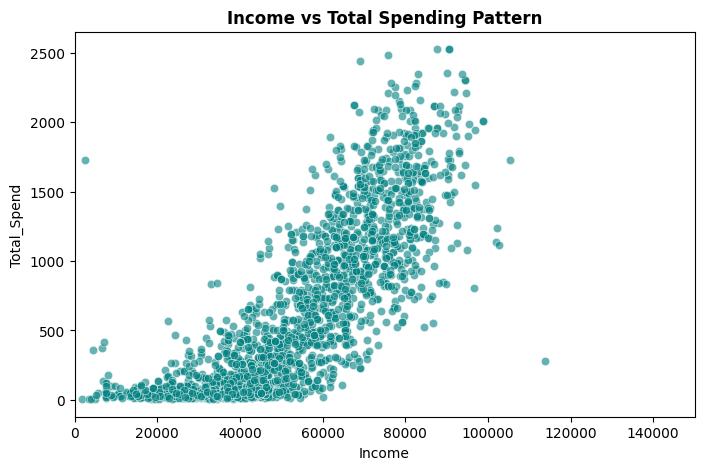

In [25]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Income', y= 'Total_Spend',alpha=0.6, color='teal')
plt.title("Income vs Total Spending Pattern",fontsize=12, fontweight='bold')
plt.xlim(0,150000)
plt.show()

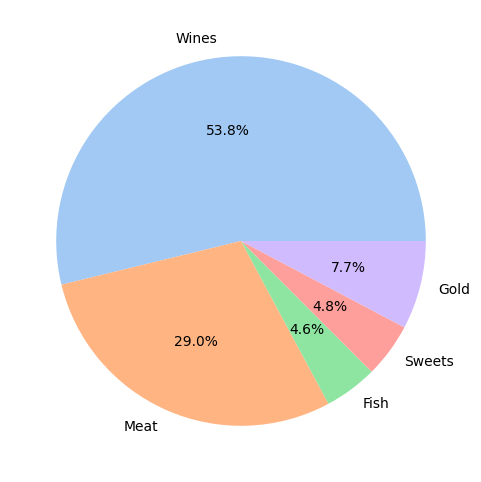

In [27]:
plt.figure(figsize=(6,6))
products=["Wines","Meat","Fish","Sweets","Gold"]
product_totals = [df['MntWines'].sum(),
                  df['MntMeatProducts'].sum(),
                  df['MntFruits'].sum(),
                  df['MntSweetProducts'].sum(),
                  df['MntGoldProds'].sum()]

plt.pie(product_totals,labels=products, autopct='%1.1f%%',colors=sns.color_palette("pastel"))
plt.show()

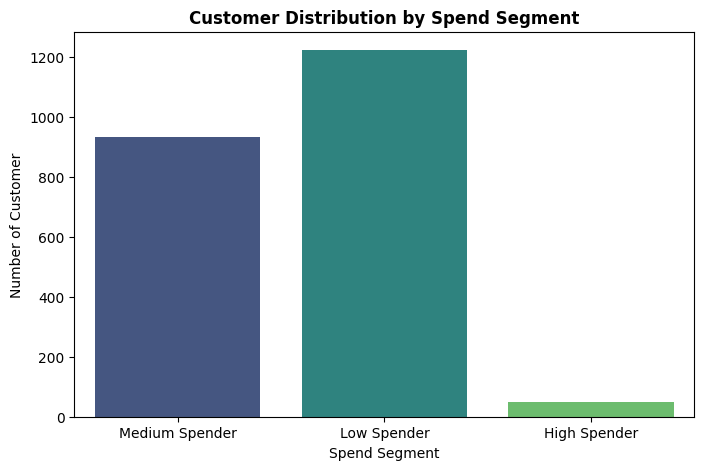

In [39]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Customer_Segment',
    hue="Customer_Segment",
    palette="viridis",
    legend=False
)

plt.title(
    "Customer Distribution by Spend Segment",
     fontsize=12,
     fontweight='bold'
)

plt.xlabel("Spend Segment")
plt.ylabel("Number of Customer")
plt.show()


In [ ]:
df=load_data()
df=cleaned_data(df)
df=create_features(df)
calculation_kpi(df)
create_visualization(df)
create_visualization(df)